# T29 -- Phase 3: cross-time KDE (T16 support-grid) normalization on real data

**Formula used (exact, per `iste.phase3_normalization`):**

```text
normalized_support(x, y, t) = Support(x, y, t) / percentile(Support_t[Support_t > 0], 95)
```

computed INDEPENDENTLY at each timestamp `t` (never pooled across timestamps), using
only that timestamp's own grid cells that actually have positive support (excluding the
large structural-zero background of a fixed search grid, which would otherwise dominate
and can even make the 95th percentile of the WHOLE grid exactly 0 for a tight cluster).
See `iste/phase3_normalization.py`'s module docstring for the full rationale and why
this specific choice (not min-max, not a hardcoded constant) was made.

This task does not decide any ranking -- it only produces a field where different
timestamps' concentration levels are directly comparable (T36 will later combine this
with other evidence).

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.particle_query import query_particle_slice
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_normalization import normalize_support_grid, DEFAULT_PERCENTILE

## 1. Load the real Stage III result + T27 grid (same as T28)

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
print(f"loaded {records.n_records} real rows; analysis grid has {len(grid)} timestamps")

import json as _json
spill_data = _json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()

loaded 240024 real rows; analysis grid has 73 timestamps


## 2. Compute raw support grids + normalize, at 8 representative sample timestamps

T0, T6, T12, T24, T36, T48, T60, T72 -- the same sampling pattern as the main real-data
notebook's visualization sections, to keep this manual-check notebook's runtime small
(computing all 73 full-grid support maps is T28's job, already done).

In [3]:
sample_hours = [0, 6, 12, 24, 36, 48, 60, 72]
sample_t_s = [grid[h] for h in sample_hours]

lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)
raw_grids = {}
norm_results = {}
t0 = time.time()
for h, t_s in zip(sample_hours, sample_t_s):
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(),
        radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    raw_grids[h] = grid_vals
    norm_results[h] = normalize_support_grid(grid_vals, t_s, percentile=DEFAULT_PERCENTILE)
t1 = time.time()
print(f"computed raw + normalized grids for {len(sample_hours)} sample timestamps in {t1-t0:.1f}s")

computed raw + normalized grids for 8 sample timestamps in 15.7s


## 3. Raw vs. normalized KDE max, across the sample -- the key T29 result

In [4]:
print(f"{'hours_before_obs':>16s} {'raw_kde_max':>12s} {'reference(p95)':>15s} {'normalized_max':>15s}")
for h in sample_hours:
    r = norm_results[h]
    print(f"{h:>16d} {r.raw_max:>12.2f} {r.reference_value:>15.2f} {r.normalized_max:>15.3f}")

raw_maxes = np.array([norm_results[h].raw_max for h in sample_hours])
norm_maxes = np.array([norm_results[h].normalized_max for h in sample_hours])
print()
print(f"raw_kde_max        range: [{raw_maxes.min():.2f}, {raw_maxes.max():.2f}]  ratio={raw_maxes.max()/raw_maxes.min():.2f}x")
print(f"normalized_kde_max  range: [{norm_maxes.min():.3f}, {norm_maxes.max():.3f}]  ratio={norm_maxes.max()/norm_maxes.min():.2f}x")

hours_before_obs  raw_kde_max  reference(p95)  normalized_max
               0      4745.00         4295.20           1.105
               6      3961.17         3327.43           1.190
              12      3176.76         2512.04           1.265
              24      2001.91         1713.17           1.169
              36      1466.93         1079.37           1.359
              48      1189.38          832.70           1.428
              60      1045.17          685.39           1.525
              72       855.31          583.33           1.466

raw_kde_max        range: [855.31, 4745.00]  ratio=5.55x
normalized_kde_max  range: [1.105, 1.525]  ratio=1.38x


## 4. Side-by-side raw vs. normalized heatmaps

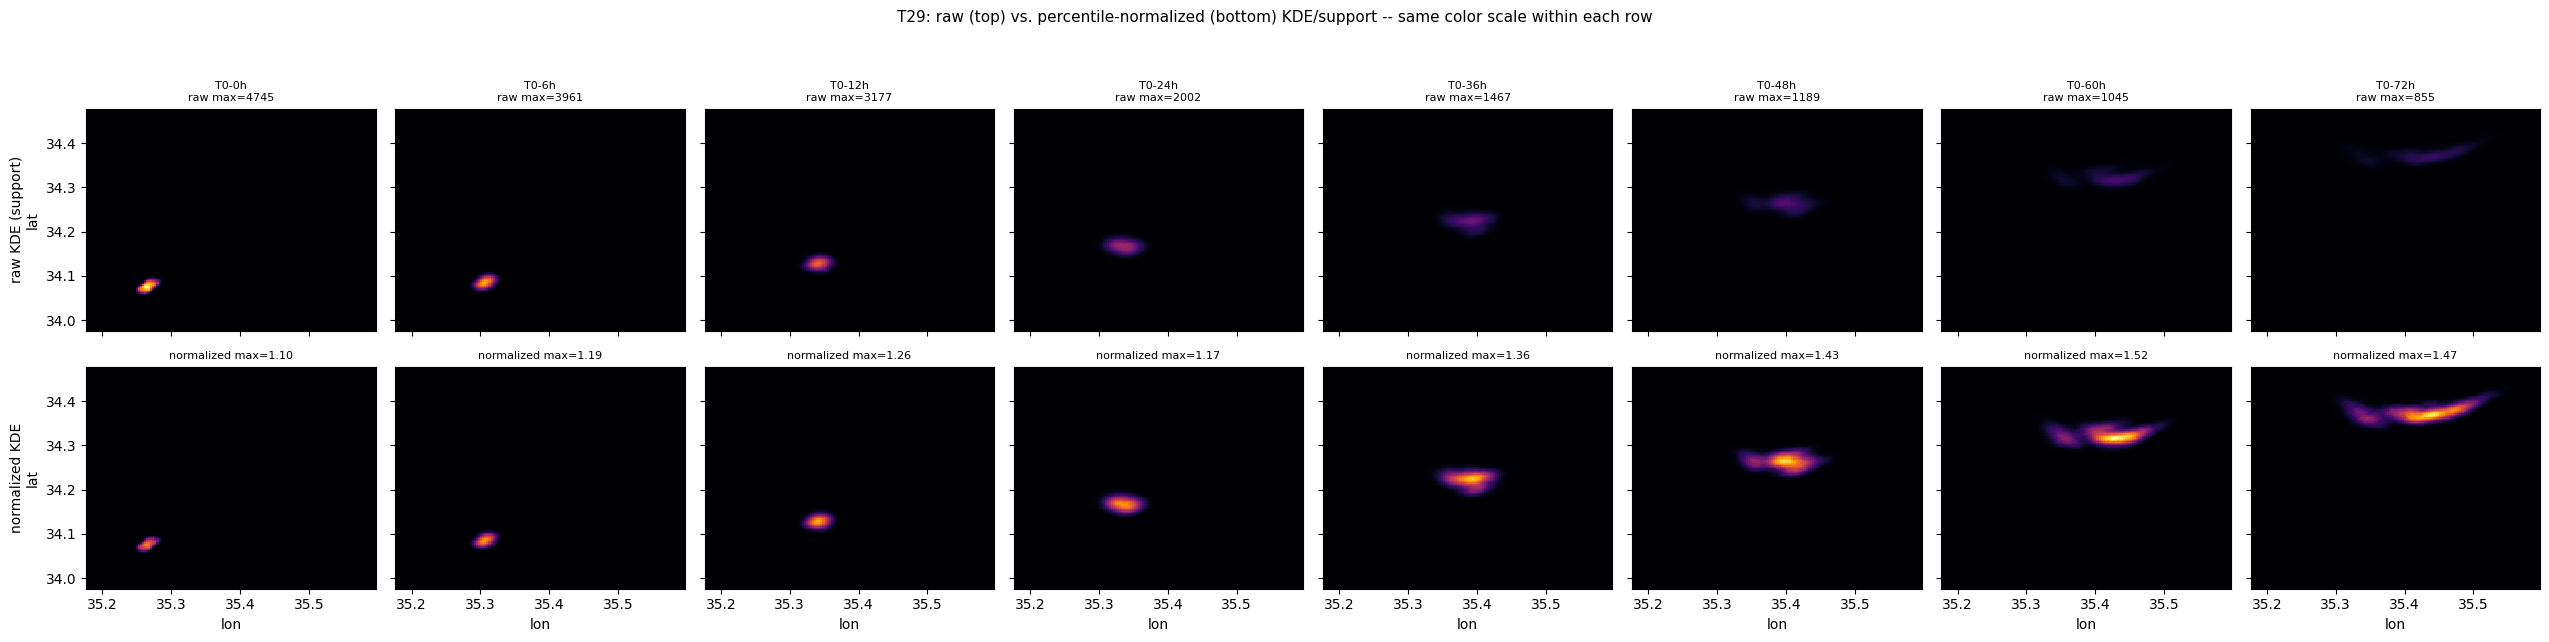

In [5]:
fig, axes = plt.subplots(2, len(sample_hours), figsize=(3.2 * len(sample_hours), 6.5), sharex=True, sharey=True)
raw_vmax = max(raw_grids[h].max() for h in sample_hours)
norm_vmax = max(np.nanmax(norm_results[h].normalized_grid) for h in sample_hours)
for col, h in enumerate(sample_hours):
    ax = axes[0, col]
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, raw_grids[h], shading="auto", cmap="inferno", vmin=0, vmax=raw_vmax)
    ax.set_title(f"T0-{h}h\nraw max={raw_grids[h].max():.0f}", fontsize=8)
    ax = axes[1, col]
    mesh2 = ax.pcolormesh(support_lon_grid, support_lat_grid, norm_results[h].normalized_grid, shading="auto", cmap="inferno", vmin=0, vmax=norm_vmax)
    ax.set_title(f"normalized max={norm_results[h].normalized_max:.2f}", fontsize=8)
    ax.set_xlabel("lon")
axes[0, 0].set_ylabel("raw KDE (support)\nlat")
axes[1, 0].set_ylabel("normalized KDE\nlat")
fig.suptitle("T29: raw (top) vs. percentile-normalized (bottom) KDE/support -- same color scale within each row", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T29_raw_vs_normalized_kde.png"), dpi=100)
plt.show()

## Known limitations (T29 scope only)

- The normalization is a documented PROTOTYPE/CONFIGURATION choice (percentile-of-
  positive-cells, default P=95), not a claim of a uniquely correct statistical answer;
  `percentile` is fully overridable.
- Normalization alone does not rank candidates -- it only makes cross-time comparison
  meaningful. Initial-condition correction (T30), persistence (T31), convergence (T32),
  dispersion-aware scoring (T33), screening normalization (T34), AIS (T35), and the
  composite score (T36) are not implemented yet.
- Computed on 8 sample timestamps here (not all 73) to keep this notebook's runtime
  small; T28's diagnostic table already covers all 73 timestamps' raw KDE summaries.
- No Stage III module, and no existing T14-T17/T25/T26 module, was modified.